**Métrica principal**: F1-score e ROC-AUC
**Protocolo**: K-Fold (k=3)

In [1]:
%matplotlib inline
import sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import numpy as np
import warnings
import time
warnings.filterwarnings("ignore")

ROOT_DIR = Path("..").resolve()
sys.path.append(str(ROOT_DIR))
sys.path.append(str(ROOT_DIR / "src"))

from src.feature_selectors  import comparar_rankings, selecionar_bandas_consenso
from src.feature_engineering import build_gold_matrix, salvar_gold
from src.preprocessing       import build_preprocessor
from src.modeling_roi        import load_roi_matrix, run_logo

K_BANDAS = 15

In [2]:
# Unidade de análise = AMOSTRA/ROI (espectro médio por amostra), conforme o
# plano [n_amostras × n_bandas]. O pixel-wise (220k pixels) foi abandonado por
# pseudo-replicação. O pré-processamento é aplicado DENTRO de cada fold na
# avaliação (anti-leakage); as versões abaixo são GLOBAIS e servem APENAS às
# visualizações exploratórias (rankings de banda e engenharia de atributos).
df_roi = load_roi_matrix()
band_cols = [c for c in df_roi.columns if c not in ("sample_id", "target")]
print(f"Matriz ROI: {df_roi.shape[0]} amostras x {len(band_cols)} bandas | "
      f"{int(df_roi['target'].sum())} resistentes\n")

PREPROCS = ["RAW", "MSC", "SavGol", "ZScore"]
_MAP_PRE = {"RAW": "raw", "MSC": "msc", "SavGol": "savigol", "ZScore": "z_score"}

def _roi_preprocessado(metodo):
    """Aplica o pré-proc globalmente — SÓ para visualização exploratória."""
    pre = build_preprocessor(_MAP_PRE[metodo])
    X = pre.fit_transform(df_roi[band_cols].values)
    out = df_roi.copy()
    out[band_cols] = X
    return out

datasets = {nome: _roi_preprocessado(nome) for nome in PREPROCS}
for nome, df in datasets.items():
    print(f"  {nome:8s}: {df['sample_id'].nunique()} amostras x {len(band_cols)} bandas (viz)")

Matriz ROI: 19 amostras x 226 bandas | 3 resistentes

  RAW     : 19 amostras x 226 bandas (viz)
  MSC     : 19 amostras x 226 bandas (viz)
  SavGol  : 19 amostras x 226 bandas (viz)
  ZScore  : 19 amostras x 226 bandas (viz)


## Etapa 1 — Ranking de bandas por MI, ANOVA e LightGBM FI

Comparação dos três métodos no dataset completo.
> Esta visualização usa TODO o dataset — apenas para exploração.
> A seleção de bandas para avaliação ocorre dentro de cada fold (células seguintes).

In [3]:
# Rankings para o método MSC — MI, ANOVA e LightGBM FI
METODO_VIZ = "MSC"
df_silver_viz = datasets[METODO_VIZ]

print(f"Calculando rankings MI, ANOVA e LightGBM para {METODO_VIZ}...")
df_ranking = comparar_rankings(df_silver_viz)

# Adiciona ranking LightGBM FI
from src.feature_selectors import rankear_bandas_lightgbm
df_lgbm = rankear_bandas_lightgbm(df_silver_viz)[['banda', 'score_lgbm', 'rank_lgbm']]
df_ranking = df_ranking.merge(df_lgbm, on='banda')

print(f"\nTop 15 bandas por rank médio MI+ANOVA+LGBM:")
display(df_ranking[['banda','rank_mi','rank_anova','rank_lgbm','rank_medio']].head(15).round(2))

Calculando rankings MI, ANOVA e LightGBM para MSC...



Top 15 bandas por rank médio MI+ANOVA+LGBM:


,banda,rank_mi,rank_anova,rank_lgbm,rank_medio
0,b188,1,22,1,11.5
1,b187,14,20,189,17.0
2,b190,8,32,191,20.0
3,b209,15,35,211,25.0
4,b191,4,47,192,25.5
5,b175,20,34,176,27.0
6,b212,13,42,213,27.5
7,b189,18,40,190,29.0
8,b186,36,24,5,30.0
9,b192,9,52,196,30.5


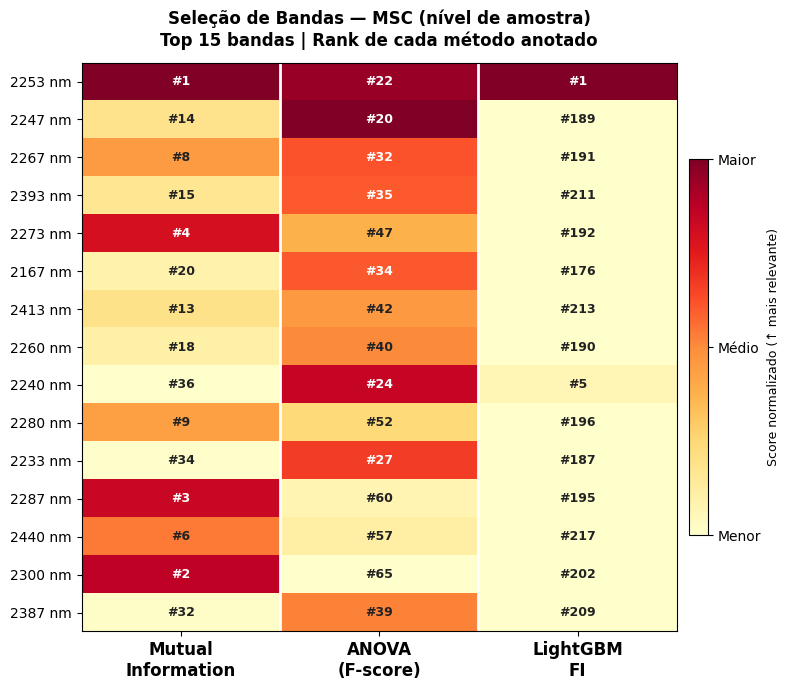

Figura salva: ranking_bandas_consenso_heatmap.png


In [4]:
# ── Heatmap de consenso: top 15 bandas × 3 métodos de seleção ────────────────
# Mostra o rank de cada banda nos 3 métodos — quanto menor o rank, mais relevante.
import matplotlib.colors as mcolors

OUTPUT_DIR = ROOT_DIR / "data" / "gold level" / "features_extraidas"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

TOP_N = 15
top15 = df_ranking.nsmallest(TOP_N, 'rank_medio').copy().reset_index(drop=True)

def norm(col):
    mn, mx = col.min(), col.max()
    return (col - mn) / (mx - mn + 1e-9)

scores_norm = np.column_stack([
    norm(top15['score_mi']).values,
    norm(top15['score_anova']).values,
    norm(top15['score_lgbm']).values,
])

fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(scores_norm, cmap='YlOrRd', aspect='auto', vmin=0, vmax=1)

ax.set_xticks([0, 1, 2])
ax.set_xticklabels(['Mutual\nInformation', 'ANOVA\n(F-score)', 'LightGBM\nFI'],
                   fontsize=12, fontweight='bold')
ax.set_yticks(range(TOP_N))

# Índice de banda ('b188') -> nm real (SisuCHEMA 1000-2500 nm, 226 bandas)
n_total_bands = len([c for c in df_silver_viz.columns
                     if c not in ['sample_id', 'target', 'block_id', 'roi_id', 'pixel_id']])
def idx_to_nm(banda):
    i = int(str(banda).lstrip('b'))
    return f"{1000 + i * (1500 / (n_total_bands - 1)):.0f} nm"

ax.set_yticklabels([idx_to_nm(row['banda']) for _, row in top15.iterrows()], fontsize=10)

ranks = np.column_stack([
    top15['rank_mi'].values.astype(int),
    top15['rank_anova'].values.astype(int),
    top15['rank_lgbm'].values.astype(int),
])
for i in range(TOP_N):
    for j in range(3):
        cor = "white" if scores_norm[i, j] > 0.6 else "#222222"
        ax.text(j, i, f"#{ranks[i, j]}", ha='center', va='center',
                fontsize=9, fontweight='bold', color=cor)

cbar = plt.colorbar(im, ax=ax, fraction=0.03, pad=0.02)
cbar.set_label('Score normalizado (↑ mais relevante)', fontsize=9)
cbar.set_ticks([0, 0.5, 1]); cbar.set_ticklabels(['Menor', 'Médio', 'Maior'])

ax.set_title(f'Seleção de Bandas — {METODO_VIZ} (nível de amostra)\n'
             f'Top {TOP_N} bandas | Rank de cada método anotado',
             fontsize=12, fontweight='bold', pad=12)
for x in [0.5, 1.5]:
    ax.axvline(x, color='white', linewidth=2)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "ranking_bandas_consenso_heatmap.png", dpi=150, bbox_inches='tight')
plt.show()
print("Figura salva: ranking_bandas_consenso_heatmap.png")

## Etapa 2 — Avaliação das 20 combinações (k=15)

**5 configs × 4 preprocessings = 20 combinações**

| Config | Seleção | Features derivadas |
|---|---|---|
| Espectros + Features Derivadas | todas bandas | Sim — mean, std, skew, kurt, derivadas, índices |
| MI (somente espectros) | k=15 por MI | Não |
| ANOVA (somente espectros) | k=15 por ANOVA | Não |
| LGBM FI (somente espectros) | k=15 por LGBM FI | Não |
| Somente espectros (baseline) | todas bandas | Não |

> Seleção de bandas ocorre **dentro de cada fold**, nos pixels de treino — sem leakage.

In [5]:
# Configurações das 5 variantes × 4 preprocessings = 20 combinações
# Avaliação no nível de AMOSTRA via LOGO-CV (cada amostra deixada de fora 1x).
# Pré-processamento e seleção de bandas ajustados DENTRO de cada fold (sem leakage).
COMBINACOES = [
    {"nome": "Espectros + Features Derivadas",        "selecao": None,    "derivadas": True},
    {"nome": f"MI k={K_BANDAS} (só espectros)",        "selecao": "mi",    "derivadas": False},
    {"nome": f"ANOVA k={K_BANDAS} (só espectros)",     "selecao": "anova", "derivadas": False},
    {"nome": f"LGBM FI k={K_BANDAS} (só espectros)",   "selecao": "lgbm",  "derivadas": False},
    {"nome": "Somente espectros (baseline)",           "selecao": None,    "derivadas": False},
]

OUTPUT_DIR = ROOT_DIR / "data" / "gold level" / "features_extraidas"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CSV_RESULTADOS = OUTPUT_DIR / "resultados_notebook06_roi.csv"

# ── Resume: carrega resultados já computados para não retroceder ─────────────
if CSV_RESULTADOS.exists():
    df_existente = pd.read_csv(CSV_RESULTADOS)
    resultados = df_existente.to_dict('records')
    ja_feitos = set(zip(df_existente['Pré-proc'], df_existente['Config']))
    print(f"Resume: {len(resultados)} resultados carregados ({len(ja_feitos)} combinações já prontas)")
else:
    resultados = []
    ja_feitos  = set()

total = len(PREPROCS) * len(COMBINACOES)
feito = 0
t0 = time.time()

for nome_pre in PREPROCS:
    for combo in COMBINACOES:
        feito += 1
        label = f"{nome_pre} | {combo['nome']}"
        chave = (nome_pre, combo["nome"])

        if chave in ja_feitos:
            print(f"  [SKIP] {label}")
            continue

        print(f"[{feito:02d}/{total}] LOGO — {label}")
        res = run_logo(
            df_roi,
            metodo_pre=_MAP_PRE[nome_pre],
            metodo_sel=combo["selecao"],
            k=K_BANDAS,
            incluir_derivadas=combo["derivadas"],
        )
        m = res["metricas"]
        resultados.append({
            "Pré-proc": nome_pre,
            "Config":   combo["nome"],
            "F1-score": m["F1"],
            "ROC-AUC":  m["ROC_AUC"],
            "Recall":   m["Recall"],
            "Precisão": m["Precisao"],
            "Acurácia": m["Acuracia"],
        })
        ja_feitos.add(chave)
        pd.DataFrame(resultados).to_csv(CSV_RESULTADOS, index=False)

elapsed = time.time() - t0
print(f"\nConcluído em {elapsed/60:.1f} min — {len(resultados)} linhas em {CSV_RESULTADOS.name}")

Resume: 20 resultados carregados (20 combinações já prontas)
  [SKIP] RAW | Espectros + Features Derivadas
  [SKIP] RAW | MI k=15 (só espectros)
  [SKIP] RAW | ANOVA k=15 (só espectros)
  [SKIP] RAW | LGBM FI k=15 (só espectros)
  [SKIP] RAW | Somente espectros (baseline)
  [SKIP] MSC | Espectros + Features Derivadas
  [SKIP] MSC | MI k=15 (só espectros)
  [SKIP] MSC | ANOVA k=15 (só espectros)
  [SKIP] MSC | LGBM FI k=15 (só espectros)
  [SKIP] MSC | Somente espectros (baseline)
  [SKIP] SavGol | Espectros + Features Derivadas
  [SKIP] SavGol | MI k=15 (só espectros)
  [SKIP] SavGol | ANOVA k=15 (só espectros)
  [SKIP] SavGol | LGBM FI k=15 (só espectros)
  [SKIP] SavGol | Somente espectros (baseline)
  [SKIP] ZScore | Espectros + Features Derivadas
  [SKIP] ZScore | MI k=15 (só espectros)
  [SKIP] ZScore | ANOVA k=15 (só espectros)
  [SKIP] ZScore | LGBM FI k=15 (só espectros)
  [SKIP] ZScore | Somente espectros (baseline)

Concluído em 0.0 min — 20 linhas em resultados_notebook06_ro

In [6]:
if 'resultados' in dir() and len(resultados) > 0:
    df_res = pd.DataFrame(resultados)
else:
    df_res = pd.read_csv(OUTPUT_DIR / "resultados_notebook06_3.csv")

COLS = ['Pré-proc', 'Config', 'F1-score', 'ROC-AUC', 'Recall', 'Precisão', 'Acurácia']
df_show = df_res[COLS].sort_values('F1-score', ascending=False)
display(df_show.round(4))

,Pré-proc,Config,F1-score,ROC-AUC,Recall,Precisão,Acurácia
8,MSC,LGBM FI k=15 (só espectros),0.5000,0.4583,0.3333,1.0000,0.8947
9,MSC,Somente espectros (baseline),0.5000,0.4583,0.3333,1.0000,0.8947
18,ZScore,LGBM FI k=15 (só espectros),0.3333,0.5312,0.3333,0.3333,0.7895
6,MSC,MI k=15 (só espectros),0.3333,0.4896,0.3333,0.3333,0.7895
2,RAW,ANOVA k=15 (só espectros),0.3077,0.5417,0.6667,0.2000,0.5263
16,ZScore,MI k=15 (só espectros),0.2857,0.4792,0.6667,0.1818,0.4737
0,RAW,Espectros + Features Derivadas,0.2857,0.4687,0.3333,0.2500,0.7368
3,RAW,LGBM FI k=15 (só espectros),0.2857,0.4792,0.3333,0.2500,0.7368
4,RAW,Somente espectros (baseline),0.2857,0.4792,0.3333,0.2500,0.7368
19,ZScore,Somente espectros (baseline),0.2857,0.5312,0.3333,0.2500,0.7368


In [7]:
print("=" * 60)
print("MELHOR RESULTADO POR PRÉ-PROCESSAMENTO — K-Fold (k=3)")
print("=" * 60)

for pre in ['MSC', 'RAW', 'SavGol', 'ZScore']:
    subset = df_res[df_res['Pré-proc'] == pre]
    if subset.empty:
        print(f"\n{pre}: sem resultados")
        continue
    melhor = subset.loc[subset['F1-score'].idxmax()]
    print(f"\n{pre}:")
    print(f"  Config   : {melhor['Config']}")
    print(f"  F1-score : {melhor['F1-score']:.4f}")
    print(f"  ROC-AUC  : {melhor['ROC-AUC']:.4f}")
    print(f"  Recall   : {melhor['Recall']:.4f}")
    print(f"  Precisão : {melhor['Precisão']:.4f}")

print("\n" + "=" * 60)
print("MELHOR GERAL")
print("=" * 60)
melhor_geral = df_res.loc[df_res['F1-score'].idxmax()]
print(f"  Pré-proc : {melhor_geral['Pré-proc']}")
print(f"  Config   : {melhor_geral['Config']}")
print(f"  F1-score : {melhor_geral['F1-score']:.4f}")
print(f"  ROC-AUC  : {melhor_geral['ROC-AUC']:.4f}")
print(f"  Recall   : {melhor_geral['Recall']:.4f}")
print(f"  Precisão : {melhor_geral['Precisão']:.4f}")

MELHOR RESULTADO POR PRÉ-PROCESSAMENTO — K-Fold (k=3)

MSC:
  Config   : LGBM FI k=15 (só espectros)
  F1-score : 0.5000
  ROC-AUC  : 0.4583
  Recall   : 0.3333
  Precisão : 1.0000

RAW:
  Config   : ANOVA k=15 (só espectros)
  F1-score : 0.3077
  ROC-AUC  : 0.5417
  Recall   : 0.6667
  Precisão : 0.2000

SavGol:
  Config   : Espectros + Features Derivadas
  F1-score : 0.0000
  ROC-AUC  : 0.3542
  Recall   : 0.0000
  Precisão : 0.0000

ZScore:
  Config   : LGBM FI k=15 (só espectros)
  F1-score : 0.3333
  ROC-AUC  : 0.5312
  Recall   : 0.3333
  Precisão : 0.3333

MELHOR GERAL
  Pré-proc : MSC
  Config   : LGBM FI k=15 (só espectros)
  F1-score : 0.5000
  ROC-AUC  : 0.4583
  Recall   : 0.3333
  Precisão : 1.0000


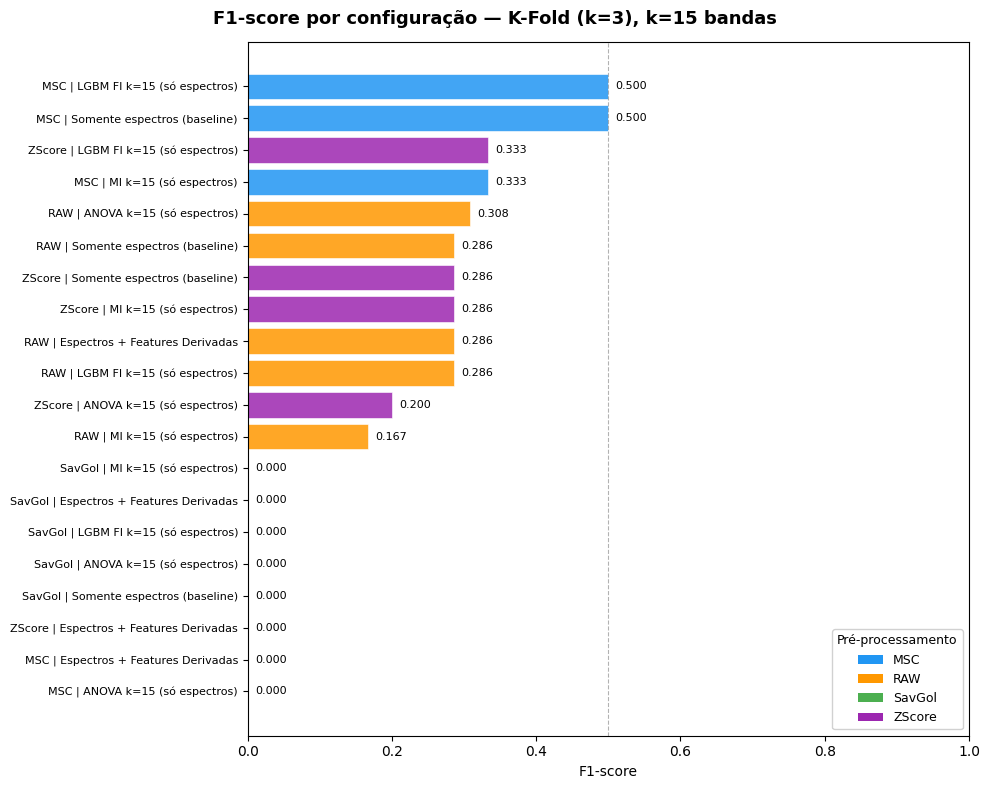

In [8]:
# Gráfico F1-score — K-Fold (k=3), todas as 20 combinações
cores_pre = {'MSC': '#2196F3', 'RAW': '#FF9800', 'SavGol': '#4CAF50', 'ZScore': '#9C27B0'}

subset = df_res.sort_values('F1-score', ascending=True)

fig, ax = plt.subplots(figsize=(10, 8))
fig.suptitle(f'F1-score por configuração — K-Fold (k=3), k={K_BANDAS} bandas',
             fontsize=13, fontweight='bold')

bars = ax.barh(
    range(len(subset)),
    subset['F1-score'].values,
    color=[cores_pre.get(p, '#607D8B') for p in subset['Pré-proc']],
    alpha=0.85,
    edgecolor='white',
    linewidth=0.5,
)
ax.set_yticks(range(len(subset)))
ax.set_yticklabels(
    [f"{row['Pré-proc']} | {row['Config']}" for _, row in subset.iterrows()],
    fontsize=8,
)
ax.set_xlabel('F1-score')
ax.axvline(0.5, color='gray', linestyle='--', linewidth=0.8, alpha=0.6)
ax.set_xlim(0, 1)

for bar, val in zip(bars, subset['F1-score'].values):
    ax.text(val + 0.01, bar.get_y() + bar.get_height()/2,
            f'{val:.3f}', va='center', fontsize=8)

from matplotlib.patches import Patch
legend_elements = [Patch(facecolor=c, label=p) for p, c in cores_pre.items()]
ax.legend(handles=legend_elements, loc='lower right', fontsize=9,
          title='Pré-processamento', title_fontsize=9, framealpha=0.9)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'comparacao_20_combinacoes_kfold.png', dpi=120, bbox_inches='tight')
plt.show()

## Etapa 3 — Salvar Gold na camada Gold

Salva 4 arquivos para o melhor pré-processamento (MSC) e para todos:
- `gold_MSC_mi_k15_espectros.csv` — k=15 bandas MI, sem features derivadas
- `gold_MSC_anova_k15_espectros.csv` — k=15 bandas ANOVA, sem features derivadas
- `gold_MSC_mi_k15_completo.csv` — k=15 bandas MI + features derivadas
- `gold_MSC_anova_k15_completo.csv` — k=15 bandas ANOVA + features derivadas

In [9]:
# ── Salva Gold apenas para as 4 melhores configurações (uma por pré-processamento) ──
# Nota: NB07 e NB08 reconstroem o Gold internamente via build_gold_matrix().
# Estes arquivos são para inspeção/exploração manual, não são consumidos pelo pipeline.
#
# Melhores configs identificadas no NB06 (maior F1 por pré-processamento):
#   MSC    → MI k=15, só espectros       (F1=0.666)
#   RAW    → baseline + derivadas        (F1=0.545)
#   SavGol → baseline + derivadas        (F1=0.256)
#   ZScore → MI k=15, só espectros       (F1=0.134)

MELHORES_GOLD = {
    "MSC":    {"selecao": "mi",  "derivadas": False, "sufixo_sel": f"mi_k{K_BANDAS}"},
    "RAW":    {"selecao": None,  "derivadas": True,  "sufixo_sel": "baseline"},
    "SavGol": {"selecao": None,  "derivadas": True,  "sufixo_sel": "baseline"},
    "ZScore": {"selecao": "mi",  "derivadas": False, "sufixo_sel": f"mi_k{K_BANDAS}"},
}

print("Salvando Gold das 4 melhores configurações...\n")

for nome_pre, cfg in MELHORES_GOLD.items():
    df_silver = datasets[nome_pre]
    sufixo_feat = "completo" if cfg["derivadas"] else "espectros"
    nome_arquivo = f"gold_{nome_pre}_{cfg['sufixo_sel']}_{sufixo_feat}.csv"
    caminho = OUTPUT_DIR / nome_arquivo

    if caminho.exists():
        print(f"  [SKIP] {nome_arquivo} já existe")
        continue

    if cfg["selecao"] is not None:
        bandas = selecionar_bandas_consenso(df_silver, k=K_BANDAS, metodo=cfg["selecao"])
    else:
        bandas = None

    salvar_gold(
        df_silver, bandas, nome_pre, cfg["sufixo_sel"], K_BANDAS,
        OUTPUT_DIR, incluir_features_derivadas=cfg["derivadas"],
    )

print("\nGold salvo com sucesso!")
print(f"Arquivos gerados em: {OUTPUT_DIR}")
print("\nArquivos Gold presentes:")
for f in sorted(OUTPUT_DIR.glob("gold_*.csv")):
    print(f"  {f.name}")

Salvando Gold das 4 melhores configurações...



  Gold salvo: gold_MSC_mi_k15_k15_espectros.csv (19 pixels × 15 features)
  [SKIP] gold_RAW_baseline_completo.csv já existe
  [SKIP] gold_SavGol_baseline_completo.csv já existe


  Gold salvo: gold_ZScore_mi_k15_k15_espectros.csv (19 pixels × 15 features)

Gold salvo com sucesso!
Arquivos gerados em: D:\IC PUC\HSI-Pipeline-Automation\data\gold level\features_extraidas

Arquivos Gold presentes:
  gold_MSC_mi_k15_k15_espectros.csv
  gold_RAW_baseline_completo.csv
  gold_SavGol_baseline_completo.csv
  gold_ZScore_mi_k15_k15_espectros.csv


## Etapa 4 — Engenharia de Atributos (Feature Engineering)

Visualização das 36 features extraídas por pixel após seleção MI k=15.

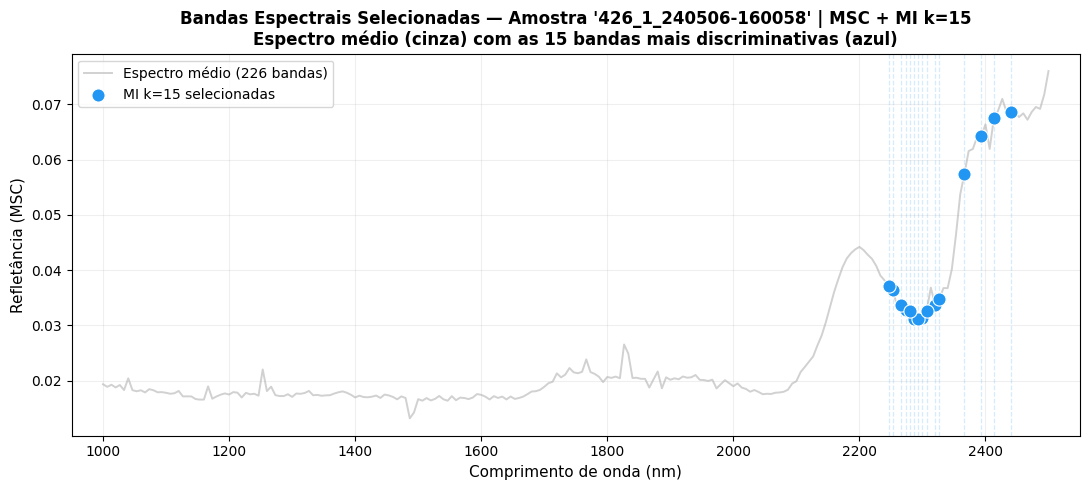

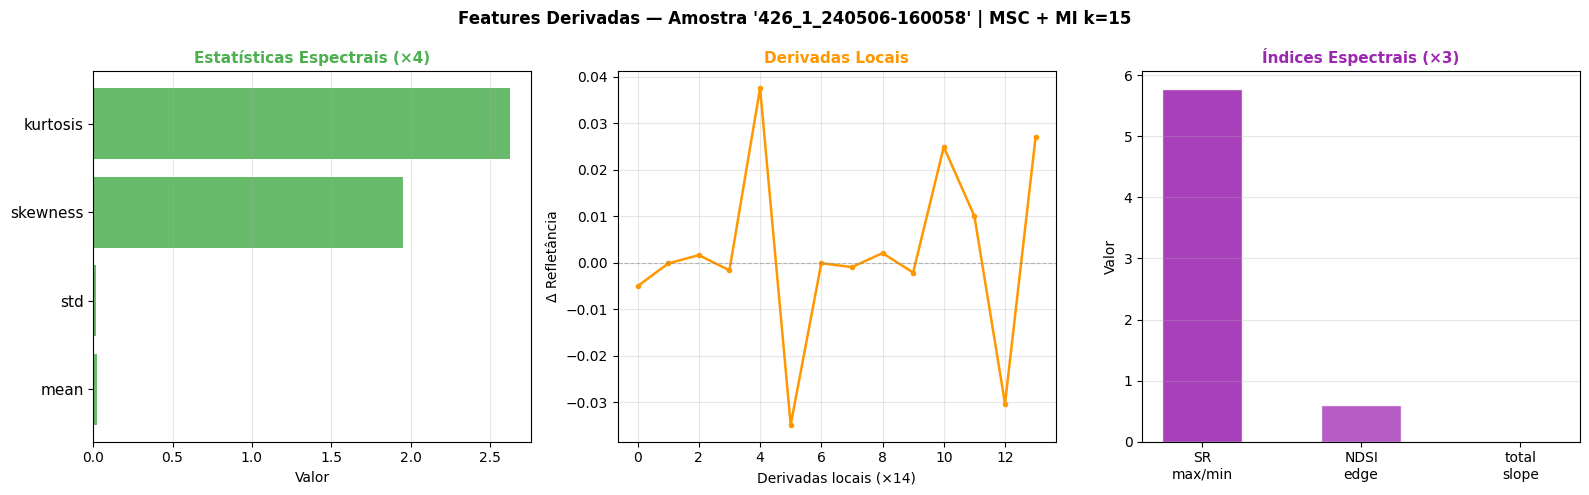

Resumo: 36 features por amostra
  Bandas: 15 | Stats: 4 | Derivadas: 14 | Índices: 3


In [10]:
# ── Visualização da engenharia de atributos (nível de AMOSTRA) ────────────────
# Figura 1: espectro médio de uma amostra com as bandas MI destacadas
# Figura 2: features derivadas (stats + derivadas + índices) dessa amostra
from src.feature_selectors   import selecionar_bandas_consenso
from src.feature_engineering import build_gold_matrix

OUTPUT_DIR = ROOT_DIR / "data" / "gold level" / "features_extraidas"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

df_silver = datasets["MSC"]            # ROI pré-processado (viz)
SAMPLE_ID_ALVO = "426_1_240506-160058"  # amostra com melhor detecção de ROI (círculo mais preciso)
if SAMPLE_ID_ALVO in df_silver["sample_id"].values:
    AMOSTRA_IDX = int(df_silver.index[df_silver["sample_id"] == SAMPLE_ID_ALVO][0])
else:
    AMOSTRA_IDX = 0                    # fallback: índice da amostra (ROI tem 19 linhas)
K = 15

bandas_mi = selecionar_bandas_consenso(df_silver, k=K, metodo="mi")

gold = build_gold_matrix(
    df_silver.iloc[[AMOSTRA_IDX]].reset_index(drop=True),
    bandas_selecionadas=bandas_mi,
    incluir_features_derivadas=True,
)
META      = ["sample_id", "target"]
feat_cols = [c for c in gold.columns if c not in META]
sample_id = df_silver.iloc[AMOSTRA_IDX]["sample_id"]

# Índice de banda ('b188') -> nm (SisuCHEMA 1000-2500 nm, 226 bandas)
def _nm(b):
    return 1000 + int(str(b).lstrip('b')) * (1500 / (len(band_cols) - 1))

espectro = df_silver.iloc[AMOSTRA_IDX][band_cols].values
wl_list  = [_nm(b) for b in band_cols]
wl_mi    = [_nm(b) for b in bandas_mi]
vals_mi  = df_silver.iloc[AMOSTRA_IDX][bandas_mi].values

# ── Figura 1: espectro médio da amostra com bandas MI destacadas ──────────────
fig1, ax1 = plt.subplots(figsize=(11, 5))
ax1.plot(wl_list, espectro, color="#CCCCCC", linewidth=1.4, alpha=0.9,
         label="Espectro médio (226 bandas)", zorder=1)
ax1.scatter(wl_mi, vals_mi, color="#2196F3", s=90, zorder=3,
            label=f"MI k={K} selecionadas", edgecolors="white", linewidth=0.8)
for x in wl_mi:
    ax1.axvline(x, color="#2196F3", alpha=0.18, linewidth=0.9, linestyle="--")
ax1.set_xlabel("Comprimento de onda (nm)", fontsize=11)
ax1.set_ylabel("Refletância (MSC)", fontsize=11)
ax1.set_title(
    f"Bandas Espectrais Selecionadas — Amostra '{sample_id}' | MSC + MI k={K}\n"
    f"Espectro médio (cinza) com as {K} bandas mais discriminativas (azul)",
    fontsize=12, fontweight="bold")
ax1.legend(fontsize=10)
ax1.grid(True, alpha=0.2)
ax1.set_xlim(950, 2550)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "feature_engineering_bandas.png", dpi=150, bbox_inches="tight")
plt.show()

# ── Figura 2: features derivadas da amostra ───────────────────────────────────
cols_stats   = ["mean", "std", "skewness", "kurtosis"]
cols_derivs  = [c for c in feat_cols if c.startswith("deriv_")]
cols_indices = ["SR_max_min", "NDSI_edge", "total_slope"]
vals_stats   = gold[cols_stats].values.flatten()
vals_derivs  = gold[cols_derivs].values.flatten()
vals_indices = np.clip(gold[cols_indices].values.flatten(), -50, 50)

fig2, axes2 = plt.subplots(1, 3, figsize=(16, 5))
fig2.suptitle(f"Features Derivadas — Amostra '{sample_id}' | MSC + MI k={K}",
              fontsize=12, fontweight="bold")

ax_s = axes2[0]
ax_s.barh(range(len(cols_stats)), vals_stats, color="#4CAF50", alpha=0.85)
ax_s.set_yticks(range(len(cols_stats))); ax_s.set_yticklabels(cols_stats, fontsize=11)
ax_s.set_title("Estatísticas Espectrais (×4)", fontsize=11, fontweight="bold", color="#4CAF50")
ax_s.set_xlabel("Valor"); ax_s.grid(axis="x", alpha=0.3)

ax_d = axes2[1]
ax_d.plot(range(len(vals_derivs)), vals_derivs, color="#FF9800", linewidth=1.8, marker=".")
ax_d.axhline(0, color="gray", linewidth=0.8, linestyle="--", alpha=0.5)
ax_d.set_xlabel(f"Derivadas locais (×{len(vals_derivs)})", fontsize=10)
ax_d.set_ylabel("Δ Refletância", fontsize=10)
ax_d.set_title("Derivadas Locais", fontsize=11, fontweight="bold", color="#FF9800")
ax_d.grid(True, alpha=0.3)

ax_i = axes2[2]
ax_i.bar(range(len(cols_indices)), vals_indices, color=["#9C27B0", "#AB47BC", "#CE93D8"],
         alpha=0.88, width=0.5, edgecolor="white")
ax_i.set_xticks(range(len(cols_indices)))
ax_i.set_xticklabels(["SR\nmax/min", "NDSI\nedge", "total\nslope"], fontsize=10)
ax_i.set_title("Índices Espectrais (×3)", fontsize=11, fontweight="bold", color="#9C27B0")
ax_i.set_ylabel("Valor"); ax_i.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "feature_engineering_derivadas_indices.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Resumo: {len(feat_cols)} features por amostra")
print(f"  Bandas: {len(bandas_mi)} | Stats: 4 | Derivadas: {len(cols_derivs)} | Índices: 3")